# Selective Admissions Model Validation & Escalation Sandbox

This notebook walks through the end-to-end simulation in `src/`—showing how strong aggregate accuracy can mask severe subgroup false-negative rates, why flattened context pushes qualified non-traditional applicants out of standard uncertainty bands, and how a **cohort-blind, context-triggered human-in-the-loop (HITL)** review policy reduces wrongful auto-rejections at low operational cost.


In [1]:
import os
import sys
from pathlib import Path

# Auto-detect Google Colab and clone the repo if running in the browser
if "google.colab" in sys.modules:
    repo_dir = Path("/content/admissions-validation-sandbox")
    if not repo_dir.exists():
        !git clone https://github.com/jasongoldfarb/admissions-validation-sandbox.git {repo_dir}
    os.chdir(repo_dir)

# Ensure repo root is on sys.path for clean `from src import ...`
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import pandas as pd
from IPython.display import Image, display
from src import baseline_repro, audit_borderline, escalation_policy, make_charts

print(f"Working directory: {Path.cwd()}")


Working directory: /Users/jasongoldfarb/dev/admissions-validation-sandbox


## 1. Setup & The Baseline Accuracy Paradox

The simulated single-institution applicant pool is anchored to the national benchmarks and modeling assumptions in **Ray, Padmanabhan, and Bouayad (*INFORMS Journal on Computing*, `INFORMSJoC/2023.0523`)**:
- **Subgroup share (NCES):** ~49.4% non-traditional / underrepresented
- **SAT distribution (College Board):** Mean `1030`, SD `235`
- **Equal underlying talent:** Identical academic and non-academic quality distributions across cohorts
- **Selectivity bar:** Top `20%` admit threshold


In [2]:
baseline_repro.main()


SESSION 1: BASELINE ADMISSIONS SCREENER (PAPER PRIORS)
Evaluation Holdout Sample: N = 3,000
Holdout SAT Mean / SD:     1029.4 / 226.7
Non-Traditional Share:     49.5%
Overall Accuracy (vs. True Readiness):      82.5%
Overall Wrongful Auto-Rejection Rate (FNR): 44.3%
----------------------------------------------------------------
Traditional Cohort (n = 1,515):
  Accuracy:                                 81.8%
  Wrongful Auto-Rejection Rate (FNR):       12.0%
  True Positive Rate (Equal Opportunity):   88.0%
----------------------------------------------------------------
Non-Traditional Cohort (n = 1,485):
  Accuracy:                                 83.2%
  Wrongful Auto-Rejection Rate (FNR):       68.5%
  True Positive Rate (Equal Opportunity):   31.5%

Saved holdout dataset & baseline scores to: outputs/baseline_applicants.csv


## 2. Flattened-Context Audit

Headline accuracy looks reassuring—even slightly higher on non-traditional applicants—yet qualified non-traditional candidates face a much higher wrongful auto-rejection rate (FNR). Below, we run the score-zone audit and compare the profiles of **missed non-traditional applicants** against **admitted traditional applicants** across both observable features and flattened context.


In [3]:
audit_borderline.main()

audited_df = pd.read_csv("outputs/audited_applicants.csv")
audited_df["ap_utilization"] = audited_df["ap_courses_taken"] / audited_df["school_ap_cap"].clip(lower=1)

missed_nontrad = audited_df[
    (audited_df["cohort"] == "non_traditional")
    & (audited_df["true_qualified"] == 1)
    & (audited_df["pred_admit"] == 0)
]
admitted_trad = audited_df[
    (audited_df["cohort"] == "traditional")
    & (audited_df["pred_admit"] == 1)
]

compare_cols = [
    "gpa",
    "test_score",
    "ap_courses_taken",
    "school_ap_cap",
    "ap_utilization",
    "outside_hours_wk",
    "upward_trajectory",
    "pred_prob",
]

comparison_df = pd.DataFrame({
    "Missed Non-Trad (Mean)": missed_nontrad[compare_cols].mean(),
    "Admitted Trad (Mean)": admitted_trad[compare_cols].mean(),
}).round(3)

comparison_df


SESSION 2: BORDERLINE BAND & QUALITATIVE CONTEXT AUDIT

1. SCORE DISTRIBUTION & ERROR CONCENTRATION BY DECISION ZONE
------------------------------------------------------------------------
1_clear_reject (<0.20)     | N=2318 (77.3%) | True Qual=227 | Wrongful Rejects=227
2_borderline (0.20-0.65)   | N= 130 ( 4.3%) | True Qual= 45 | Wrongful Rejects= 33
3_clear_admit (>0.65)      | N= 552 (18.4%) | True Qual=315 | Wrongful Rejects=  0

2. WHERE QUALIFIED APPLICANTS GET MISSED (COHORT x ZONE)
------------------------------------------------------------------------

Cohort: TRADITIONAL (Total Qualified = 251, Total Missed = 30 [12.0%])
  1_clear_reject (<0.20)     | Qualified in Zone= 21 | Wrongfully Auto-Rejected= 21 ( 8.4% of cohort qualified)
  2_borderline (0.20-0.65)   | Qualified in Zone= 15 | Wrongfully Auto-Rejected=  9 ( 3.6% of cohort qualified)
  3_clear_admit (>0.65)      | Qualified in Zone=215 | Wrongfully Auto-Rejected=  0 ( 0.0% of cohort qualified)

Cohort: NON_TRADITION

,Missed Non-Trad (Mean),Admitted Trad (Mean)
gpa,3.442,3.673
test_score,1119.478,1275.803
ap_courses_taken,2.357,7.938
school_ap_cap,3.987,12.051
ap_utilization,0.593,0.660
outside_hours_wk,17.041,3.216
upward_trajectory,0.491,0.163
pred_prob,0.058,0.931


## 3. Cohort-Blind Escalation Policy

Instead of routing on a demographic or cohort label, the escalation policy routes purely on **observable educational and life constraints**:
- **Context-constrained flag:** `school_ap_cap <= 6` **or** `outside_hours_wk >= 10` → review band `[0.04, 0.65]`
- **All other applicants:** standard review band `[0.20, 0.65]`


In [4]:
escalation_policy.main()

tradeoff_df = pd.read_csv("outputs/escalation_tradeoff.csv")
display_cols = ["policy", "escalated_pct", "escalated_count", "overall_accuracy", "trad_fnr", "nontrad_fnr"]

formatted = tradeoff_df[display_cols].copy()
for col in ["escalated_pct", "overall_accuracy", "trad_fnr", "nontrad_fnr"]:
    formatted[col] = (formatted[col] * 100).round(1).astype(str) + "%"

formatted


SESSION 3: HUMAN-IN-THE-LOOP ESCALATION SIMULATION (Human Acc = 92%)

1. STANDARD PROBABILITY REVIEW BAND SWEEP
------------------------------------------------------------------------------
Policy                          | Escalated | Overall Acc | Trad FNR | NonTrad FNR
------------------------------------------------------------------------------
No Escalation (Baseline)        |     0.0% |      82.5% |   12.0% |      68.5%
Narrow Band [0.35, 0.65]        |     2.6% |      83.7% |   10.8% |      65.8%
Moderate Band [0.20, 0.65]      |     4.3% |      84.3% |    8.8% |      61.9%
Wide Band [0.10, 0.70]          |     6.7% |      85.3% |    7.2% |      56.0%
Broad Band [0.05, 0.75]         |     9.4% |      86.1% |    6.0% |      51.2%
Very Broad [0.02, 0.80]         |    12.8% |      86.9% |    4.4% |      45.5%
Full Human Review [0.00, 1.00]  |   100.0% |      91.5% |    8.4% |       9.5%

2. CONTEXT-AWARE ESCALATION POLICY (OBSERVABLE CONTEXT PROXIES)
-----------------------------

,policy,escalated_pct,escalated_count,overall_accuracy,trad_fnr,nontrad_fnr
0,No Escalation (Baseline),0.0%,0,82.5%,12.0%,68.5%
1,"Narrow Band [0.35, 0.65]",2.6%,79,83.7%,10.8%,65.8%
2,"Moderate Band [0.20, 0.65]",4.3%,130,84.3%,8.8%,61.9%
3,"Wide Band [0.10, 0.70]",6.7%,202,85.3%,7.2%,56.0%
4,"Broad Band [0.05, 0.75]",9.4%,282,86.1%,6.0%,51.2%
5,"Very Broad [0.02, 0.80]",12.8%,384,86.9%,4.4%,45.5%
6,"Full Human Review [0.00, 1.00]",100.0%,3000,91.5%,8.4%,9.5%
7,Context-Aware Band (AP Cap <=6 or Work >=10h: ...,6.4%,193,85.5%,8.4%,50.0%


## 4. Publication Visuals

Generate and render the visual summary comparing reader workload against accuracy and wrongful auto-rejection rates.


Saved charts to:
  - outputs/chart1_aggregate_vs_subgroup.png
  - outputs/chart2_escalation_tradeoff.png


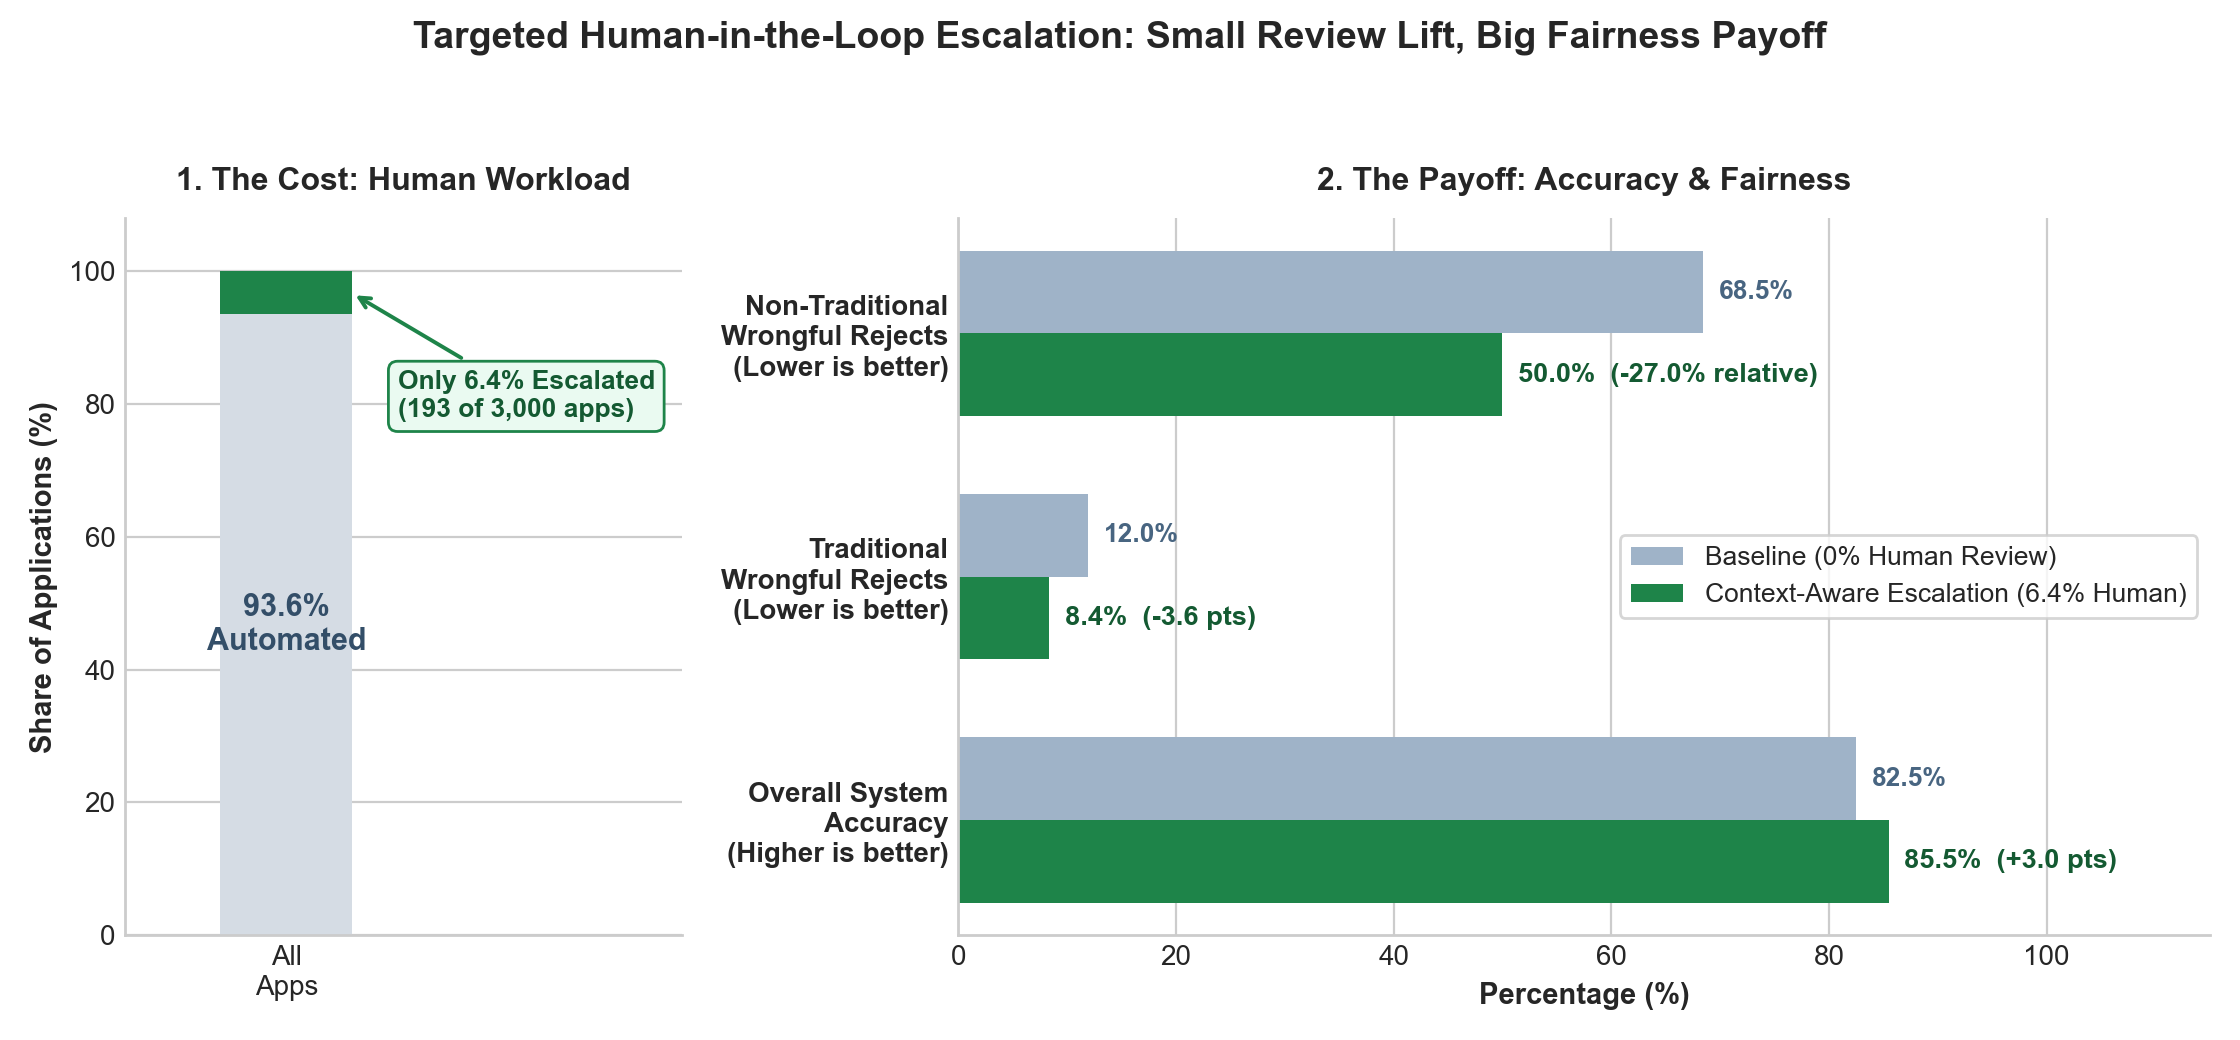

In [5]:
make_charts.main()
display(Image(filename="outputs/chart2_escalation_tradeoff.png"))


## 5. Operational Sensitivity Sandbox: Staffing vs. Fairness

In practice, an admissions office sets these thresholds around reader bandwidth and calibration, not just model scores. Adjust the knobs below and re-run the cell to test three common operational scenarios:

1. **The Budget Crunch:** Keep manual review under **5%** of applications (`<= 150` files) by tightening `low_floor` and `high_ceil`—how much missed talent can you still rescue?
2. **Reader Fatigue:** Widen the band to review **12%+** of the pool, then drop `human_acc` from `0.92` to `0.85`—does expanding the band still improve overall accuracy?
3. **Context Definition:** Tighten or loosen `ap_cap_thresh` and `work_hours_thresh` to see how sensitive workload and FNR are to how "context-constrained" is defined.


In [6]:
# --- Tunable Policy Knobs ---
ap_cap_thresh = 6       # Trigger lower floor if school offers <= N APs
work_hours_thresh = 10  # Trigger lower floor if outside work/care >= N hrs/wk
low_floor = 0.04        # Lower review-band floor for context-constrained files
high_ceil = 0.65        # Upper review-band ceiling for borderline admits
human_acc = 0.92        # Assumed human reader accuracy (try 0.85 vs. 0.95)
# ----------------------------

df = pd.read_csv("outputs/audited_applicants.csv")

baseline_stats = escalation_policy.evaluate_policy(
    df, pd.Series(False, index=df.index), human_review_accuracy=human_acc, seed=42
)

has_context = (df["school_ap_cap"] <= ap_cap_thresh) | (df["outside_hours_wk"] >= work_hours_thresh)
custom_mask = (
    ((~has_context) & (df["pred_prob"] >= 0.20) & (df["pred_prob"] <= high_ceil))
    | (has_context & (df["pred_prob"] >= low_floor) & (df["pred_prob"] <= high_ceil))
)

custom_stats = escalation_policy.evaluate_policy(
    df, custom_mask, human_review_accuracy=human_acc, seed=42
)

summary = pd.DataFrame({
    "Baseline (0% Escalated)": [
        f"{baseline_stats['escalated_pct']:.1%} ({baseline_stats['escalated_count']:,})",
        f"{baseline_stats['overall_accuracy']:.1%}",
        f"{baseline_stats['trad_fnr']:.1%}",
        f"{baseline_stats['nontrad_fnr']:.1%}",
    ],
    "Your Custom Policy": [
        f"{custom_stats['escalated_pct']:.1%} ({custom_stats['escalated_count']:,})",
        f"{custom_stats['overall_accuracy']:.1%}",
        f"{custom_stats['trad_fnr']:.1%}",
        f"{custom_stats['nontrad_fnr']:.1%}",
    ],
}, index=[
    "Applications Escalated",
    "Overall Accuracy",
    "Traditional Wrongful Reject (FNR)",
    "Non-Traditional Wrongful Reject (FNR)",
])

summary


,Baseline (0% Escalated),Your Custom Policy
Applications Escalated,0.0% (0),6.4% (193)
Overall Accuracy,82.5%,85.5%
Traditional Wrongful Reject (FNR),12.0%,8.4%
Non-Traditional Wrongful Reject (FNR),68.5%,50.0%
